# Models for Section 5: LG and Samsung TVs

This notebook estimates the models for Section 5 of the report. It follows the exploration in `02_preliminary_analysis.py` and uses the data files built by `01_build_tv_dataset.py`.

The exploration split LG's shortfall in TV purchases against Samsung into two parts with an accounting identity. About 70% comes from fewer visits reaching LG's models and about 27% from LG's lower conversion. The models examine each part with regressions that compare like with like more closely than the raw rates.

1. **Conversion.** Does LG convert less than Samsung conditional on the observed browsing state, the price and the week (Model 1)? Among the models one shopper opened in one visit, is the LG model less often the one bought (Model 2)?
2. **Considerations per product.** Does an observed LG model draw fewer considerations than an observed Samsung model at the same price (Model 3)? This is a comparison across products. It is related to the reach part of the identity but measures something different, as Section 5 explains.

Model 4 is an optional extension. It describes how traffic and conversion move when the same model's recorded price changes, under assumptions about prices on days without events that Section 6 sets out.

All models are descriptive. None of them identifies what would happen if LG changed its price, placement, assortment or pages.

**How to run it.** Run `01_build_tv_dataset.py` first, then run this notebook from the `Marketing-Project` folder. It needs pandas, numpy, scipy, statsmodels and matplotlib, and it takes about a minute.

**Inputs.** `tv_considerations.csv`, `tv_considerations_top_models.csv` and `tv_events_clean.csv`, all in `../data/01_LG_Electronics_Appliances/`.

**Outputs.** Tables 5.1 to 5.8, Figure 5.1 and `exhibit_index.csv` in `results/models/`. The index names the file each exhibit is built from.

**Timing of the controls.** Every control is known when the shopper first opens the model, with one stated exception. `top_model` is computed from the two months as a whole, so it is a retrospective split of the sample. It is used for the M4 interaction, the top-model and other-model files, and as a covariate in Model 2, and it never describes what the shopper could see. Nothing that happens after the first view enters a model as a control.

The record of which specification choices were made before and after seeing these results is in Section 8.

## Inference convention

The procedures below were fixed before the conclusions were written. Each conclusion in this notebook names the procedure it rests on and reports the sensitivity next to it.

| Model | Primary procedure | Sensitivity reported beside it |
| --- | --- | --- |
| Model 1 and Model 4a (considerations) | Standard errors clustered by user and by TV model at the same time (two-way, the convention of the exploration), with normal critical values | A wild cluster bootstrap over TV models, one-way by model |
| Model 1 on the 13 top models | The wild cluster bootstrap over models, because two-way clustering with 13 model clusters is unreliable | Two-way clustered errors |
| Model 2 (conditional logit) | A two-way sandwich by user and by model built from scores centred within each visit | One-way errors by user and by model, model-based errors checked against statsmodels, and a bootstrap that resamples users |
| Model 2 (linear model with visit fixed effects) | Two-way clustered errors | None |
| Model 3 (one row per product) | Heteroskedasticity-robust errors (HC1) | A bootstrap that resamples shoppers, which lets products share shoppers |
| Model 4b and 4c (product panels) | Errors clustered by model | None |

The wild bootstrap and the two-way errors allow different kinds of dependence. The two-way errors let rows of the same user and rows of the same model be related. The wild bootstrap lets rows of the same model be related but treats different models as independent, even when they share a shopper. Their p-values therefore answer slightly different questions and are reported side by side, with neither substituted for the other.

## 1. Data and variables

A row of `tv_considerations.csv` is a consideration, meaning one shopper, in one visit, opening one TV model, timed at the first view. Models 1, 3 and 4 use the 74,712 LG and Samsung considerations. Model 2 uses all six brands.

The cell below builds the variables the models need from the columns of the data file.

| Variable | Meaning |
| --- | --- |
| `purchased_pp` | 100 if the model was bought in the same visit, 0 otherwise |
| `lg` | 1 for an LG model, 0 for a Samsung model |
| `week` | Calendar week of the first view, from week 40 (starting Tuesday 1 October) to week 48 (25 to 30 November, which includes Black Friday) |
| `log_price` | Natural log of the price at the first view |
| `position` | first_tv, after_same_brand_only or after_other_brand, from `position_in_session` |
| `tvs_before` | Number of other TV models opened earlier in the visit, grouped as 0, 1, 2, 3 to 4, and 5 or more |
| `rival_opened_before` | The other main brand was opened earlier in the visit (Samsung for an LG row, LG for a Samsung row) |
| `own_other_model_opened_before` | Another model of the row's own brand was opened earlier in the visit |
| `price_band` | The five price bands used in the exploration |
| `visit` | The user and session identifiers together, since a few session IDs are shared by two users |

The two symmetric history variables matter. In the data file `samsung_opened_before` means "the rival was opened" on an LG row but "another of its own models was opened" on a Samsung row. Using it directly would give the two brands different meanings for the same coefficient, so the models use `rival_opened_before` and `own_other_model_opened_before` instead.

In [1]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
OUT = Path('results') / 'models'
(OUT / 'tables').mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
for old in (OUT / 'tables').glob('T5_*.csv'):
    old.unlink()
F_CONS, F_TOP, F_EV = 'tv_considerations.csv', 'tv_considerations_top_models.csv', 'tv_events_clean.csv'
SEED = 2026
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e4e4', 'axes.axisbelow': True, 'savefig.dpi': 200})

cons = pd.read_csv(DATA_DIR / F_CONS, parse_dates=['first_view'])
top_keys = pd.read_csv(DATA_DIR / F_TOP, usecols=['user_id', 'session_id', 'product_id'])
events = pd.read_csv(DATA_DIR / F_EV, parse_dates=['event_time'])
events['visit'] = events['user_id'] + '|' + events['session_id']

cons['visit'] = cons['user_id'] + '|' + cons['session_id']
cons['purchased_pp'] = 100 * cons['purchased']
cons['log_price'] = np.log(cons['price'])
cons['week'] = cons['first_view'].dt.isocalendar().week.astype(int)
cons['lg'] = (cons['brand_group'] == 'lg').astype(int)
cons['other_four'] = (cons['brand_group'] == 'other_four').astype(int)
cons['first_tv'] = (cons['position_in_session'] == 'first_tv').astype(int)
cons['position'] = pd.Categorical(cons['position_in_session'], ['first_tv', 'after_same_brand_only', 'after_other_brand'])
cons['tvs_before'] = pd.cut(cons['tvs_opened_before'], [-1, 0, 1, 2, 4, np.inf],
                            labels=['0', '1', '2', '3 to 4', '5 or more'])
cons['price_band'] = pd.cut(cons['price'], [0, 300, 450, 650, 1000, np.inf],
                            labels=['Under 300', '300 to 450', '450 to 650', '650 to 1,000', 'Over 1,000'])

ls = cons[cons['brand_group'].isin(['lg', 'samsung'])].reset_index(drop=True)
is_lg = ls['brand_group'] == 'lg'
ls['rival_opened_before'] = np.where(is_lg, ls['samsung_opened_before'], ls['lg_opened_before'])
ls['own_other_model_opened_before'] = np.where(is_lg, ls['lg_opened_before'], ls['samsung_opened_before'])
top_set = set(map(tuple, top_keys.to_numpy()))
ls['in_top_file'] = [k in top_set for k in zip(ls['user_id'], ls['session_id'], ls['product_id'])]
assert (ls['in_top_file'] == (ls['top_model'] == 1)).all()

print(f"{len(cons):,} considerations in all, {len(ls):,} of them LG or Samsung "
      f"({ls['lg'].sum():,} LG and {(1 - ls['lg']).sum():,} Samsung)")
print(f"{ls['product_id'].nunique()} LG and Samsung models observed with at least one view, {ls['user_id'].nunique():,} users, "
      f"weeks {ls['week'].min()} to {ls['week'].max()}")

115,711 considerations in all, 74,712 of them LG or Samsung (22,213 LG and 52,499 Samsung)
196 LG and Samsung models observed with at least one view, 35,871 users, weeks 40 to 48


## 2. Helper functions

**`ols2`** estimates a linear model by ordinary least squares with standard errors clustered by user and by model.

**`wild_p`** gives the p-value of a wild cluster bootstrap over TV models for one coefficient. The steps are these.
1. Estimate the model without the variable being tested, which imposes the hypothesis that its coefficient is zero.
2. Build a new outcome by adding the residuals back with a random sign, the same sign for every row of the same TV model.
3. Re-estimate the full model on the new outcome and record the t-statistic of the tested coefficient, using errors clustered by model.
4. Repeat 9,999 times. The p-value is the share of repetitions whose t-statistic is at least as large, in absolute value, as the one in the real data.

With 16 or fewer models the function tries every pattern of signs (8,192 patterns for 13 models). This removes simulation noise from the p-value. The test is still an approximation whose accuracy depends on the number of models and on how evenly their rows are spread. The function works with sums by model, so it never reruns a regression, and it was checked against a version that reruns every regression.

**`save_table`** saves a table to `results/models/tables/` and records the files it is built from.

In [2]:
EXHIBITS = []


def save_table(tid, title, df, src):
    path = OUT / 'tables' / f"T{tid.replace('.', '_')}.csv"
    df.to_csv(path)
    EXHIBITS.append({'Exhibit': f'Table {tid}', 'Title': title, 'Built from': ', '.join(src)})
    print(f'Table {tid}. {title}\nBuilt from {", ".join(src)}. Saved to {path}')
    return df


def ols2(formula, d):
    groups = np.column_stack([pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])
    return smf.ols(formula, d).fit(cov_type='cluster', cov_kwds={'groups': groups})


def wild_p(formula, d, term='lg', draws=9999, seed=SEED):
    m = smf.ols(formula, d)
    j = m.exog_names.index(term)
    z, X, y = m.exog[:, j], np.delete(m.exog, j, axis=1), m.endog
    XtX_inv = np.linalg.pinv(X.T @ X)
    u = y - X @ (XtX_inv @ (X.T @ y))
    zt = z - X @ (XtX_inv @ (X.T @ z))
    S = zt @ zt
    codes, uniq = pd.factorize(d['product_id'])
    G = len(uniq)
    c = np.bincount(codes, weights=zt * u, minlength=G)
    q = np.bincount(codes, weights=zt * zt, minlength=G)
    Dm = np.zeros((G, X.shape[1])); np.add.at(Dm, codes, X * zt[:, None])
    Am = np.zeros((G, X.shape[1])); np.add.at(Am, codes, X * u[:, None])
    B = Dm @ XtX_inv @ Am.T

    def tstat(W):
        N = W * c - W @ B.T
        beta = (W @ c) / S
        s = N - beta[:, None] * q[None, :]
        return beta / (np.sqrt(G / (G - 1) * (s ** 2).sum(1)) / S)

    t0 = tstat(np.ones((1, G)))[0]
    W = (np.array(list(itertools.product([-1.0, 1.0], repeat=G))) if G <= 16
         else np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, G)))
    t_star = np.concatenate([tstat(W[i:i + 2000]) for i in range(0, len(W), 2000)])
    return float(np.mean(np.abs(t_star) >= abs(t0) - 1e-12)), G


def coef_row(res, term='lg', label=None, extra=None):
    b, se = res.params[term], res.bse[term]
    out = {'Coefficient (pp)': b, 'Standard error (pp)': se, '95% CI low (pp)': b - 1.96 * se,
           '95% CI high (pp)': b + 1.96 * se, 'p-value, two-way clustered': res.pvalues[term], 'Considerations': int(res.nobs)}
    out.update(extra or {})
    return pd.Series(out, name=label)

## 3. Model 1. Conversion conditional on observed browsing state, price and week

### 3.1 Specification

Model 1 is a linear probability model. The outcome is 100 if the model was bought and 0 if not, so each coefficient is a difference in conversion in percentage points. Its four versions add controls in steps, so that the reader can see how much each group of controls changes LG's coefficient.

| Version | Controls added | Why |
| --- | --- | --- |
| M1 | None | Reproduces the raw gap between LG and Samsung |
| M2 (baseline) | Position in the visit, log price, week fixed effects | Position measures how far into the search the shopper is, price separates cheap and expensive models, and the week absorbs shifts in conversion that are common to all models in that week |
| M3 (extended) | The detailed browsing history in place of position (TVs opened before, rival opened before, own other model opened before, one of the other four opened before), and returning visitor | Tests whether a finer description of the search changes the result |
| M4 | M3 plus top model and LG × top model | Asks whether LG's gap differs among the most-considered models, using the retrospective top-model split |

Model 1 compares rows that share the same observed browsing state, price band and week. It does not hold the individual shopper, the model's specifications, stock or the shopper's intent fixed. Week fixed effects absorb what all models share in a given week, and they do not absorb promotions of individual models.

Three things are deliberately left out. Model fixed effects are left out because they would absorb the brand. Anything that happens after the first view is left out, such as carts or what was bought. The number of TVs opened in the whole visit is left out because it partly reflects the outcome, since shoppers who buy often stop browsing.

In [3]:
HISTORY = ('C(tvs_before) + rival_opened_before + own_other_model_opened_before + other_four_opened_before'
           ' + returning_visitor')
SPEC = {
    'M1': 'purchased_pp ~ lg',
    'M2': 'purchased_pp ~ lg + C(position) + log_price + C(week)',
    'M3': f'purchased_pp ~ lg + {HISTORY} + log_price + C(week)',
    'M4': f'purchased_pp ~ lg + {HISTORY} + log_price + C(week) + top_model + lg:top_model',
}
fits = {k: ols2(f, ls) for k, f in SPEC.items()}
wild = {k: wild_p(f, ls)[0] for k, f in SPEC.items()}
wild_inter = wild_p(SPEC['M4'], ls, term='lg:top_model')[0]

LABELS = {
    'lg': 'LG (against Samsung)',
    'C(position)[T.after_same_brand_only]': 'Position: after other models of the same brand only',
    'C(position)[T.after_other_brand]': 'Position: after a TV of another brand',
    'C(tvs_before)[T.1]': 'TVs opened before: 1',
    'C(tvs_before)[T.2]': 'TVs opened before: 2',
    'C(tvs_before)[T.3 to 4]': 'TVs opened before: 3 to 4',
    'C(tvs_before)[T.5 or more]': 'TVs opened before: 5 or more',
    'rival_opened_before': 'Rival main brand opened before',
    'own_other_model_opened_before': 'Own other model opened before',
    'other_four_opened_before': 'One of the other four brands opened before',
    'returning_visitor': 'Returning visitor',
    'log_price': 'Log price at the first view',
    'top_model': 'Top model (retrospective split)',
    'lg:top_model': 'LG × top model',
}
cols = {}
for k, r in fits.items():
    col = {label: f"{r.params[term]:.3f} ({r.bse[term]:.3f})" for term, label in LABELS.items() if term in r.params}
    col['Week fixed effects'] = 'yes' if 'C(week)' in SPEC[k] else 'no'
    col['p for LG, two-way clustered'] = f"{r.pvalues['lg']:.3f}"
    col['p for LG, wild bootstrap over models'] = f"{wild[k]:.3f}"
    col['p for LG × top model, two-way clustered'] = f"{r.pvalues['lg:top_model']:.3f}" if k == 'M4' else ''
    col['p for LG × top model, wild bootstrap over models'] = f"{wild_inter:.3f}" if k == 'M4' else ''
    col['Considerations'] = f"{int(r.nobs):,}"
    col['R-squared'] = f"{r.rsquared:.4f}"
    cols[k] = col
t51 = pd.DataFrame(cols)
t51 = t51.loc[[i for i in list(LABELS.values()) + list(t51.index) if i in t51.index]]
t51 = t51[~t51.index.duplicated()].fillna('')
t51 = save_table('5.1', 'Model 1. Conversion of LG and Samsung considerations, linear probability model (pp)', t51, [F_CONS])
display(t51)
for k in ['M2', 'M3']:
    b, se = fits[k].params['lg'], fits[k].bse['lg']
    print(f"{k}: LG {b:.2f} pp, 95% CI {b - 1.96 * se:.2f} to {b + 1.96 * se:.2f}, two-way p {fits[k].pvalues['lg']:.3f}, "
          f"wild bootstrap p {wild[k]:.3f}")

Table 5.1. Model 1. Conversion of LG and Samsung considerations, linear probability model (pp)
Built from tv_considerations.csv. Saved to results/models/tables/T5_1.csv


,M1,M2,M3,M4
LG (against Samsung),-0.860 (0.384),-0.517 (0.291),-0.521 (0.290),-0.344 (0.236)
Position: after other models of the same brand only,,-1.482 (0.133),,
Position: after a TV of another brand,,-2.076 (0.134),,
TVs opened before: 1,,,-1.294 (0.184),-1.252 (0.183)
TVs opened before: 2,,,-2.247 (0.306),-2.159 (0.289)
TVs opened before: 3 to 4,,,-2.126 (0.284),-1.988 (0.294)
TVs opened before: 5 or more,,,-2.515 (0.325),-2.327 (0.313)
Rival main brand opened before,,,-0.139 (0.147),-0.166 (0.148)
Own other model opened before,,,0.199 (0.174),0.246 (0.181)
One of the other four brands opened before,,,-0.083 (0.215),-0.136 (0.211)


M2: LG -0.52 pp, 95% CI -1.09 to 0.05, two-way p 0.075, wild bootstrap p 0.124
M3: LG -0.52 pp, 95% CI -1.09 to 0.05, two-way p 0.072, wild bootstrap p 0.122


### What Model 1 shows

Conditioning on position in the visit, price and week reduces LG's coefficient from −0.86 to −0.52 points. In the baseline (M2) the 95% interval runs from −1.09 to 0.05, with a two-way clustered p-value of 0.075 and a wild bootstrap p-value of 0.12. The extended version (M3) gives the same −0.52 points (p = 0.072 and 0.12). The point estimate says that LG converts about half a point less than Samsung among considerations with the same observed browsing state, price and week. In the baseline this difference is not significant at the 5% level under either procedure.

The other coefficients behave as the exploration suggested. A model opened after another TV converts 1.5 to 2.1 points less than the first TV of a visit, and conversion falls as more TVs have been opened before. A 10% higher price goes with about 0.09 points lower conversion (−0.93 × 0.095). Returning visitors convert about 0.9 points more.

M4 asks whether LG's gap differs among the 13 top models. The interaction is −0.26 points, with a two-way p-value of 0.61 and a wild bootstrap p-value of 0.67, so the data give no evidence that the conditional gap differs between top models and the rest. The larger raw gap among top models (−1.03 against −0.48 points) shrinks to −0.50 against −0.35 points once position, price and week are held fixed (Table 5.4).

Each coefficient appears with its standard error in parentheses. The coefficients on the week fixed effects are not shown.

### 3.2 Diagnostic of the linear model

A linear probability model can produce fitted probabilities below 0 or above 100. That does not invalidate an average difference between LG and Samsung, but it limits how far individual fitted probabilities can be read. The table reports how often it happens, and the logit versions in Table 5.4 give average differences that cannot leave the range. The fitted values are reported as they are and are not clipped.

The comparison also needs LG and Samsung considerations in every combination of the controls. The second part of the table counts the considerations of each brand in each cell of position in the visit by price band, and of TVs opened before by price band.

In [4]:
diag_rows = []
for k in ['M2', 'M3']:
    fv = fits[k].fittedvalues
    diag_rows.append({'Version': k, 'Fitted values below 0 (%)': 100 * (fv < 0).mean(),
                      'Fitted values above 100 (%)': 100 * (fv > 100).mean(),
                      'Lowest fitted value (pp)': fv.min(), 'Highest fitted value (pp)': fv.max()})
fit_range = pd.DataFrame(diag_rows).set_index('Version').round(2)
support = []
for name, var in [('Position in the visit', 'position'), ('TVs opened before', 'tvs_before')]:
    cell = ls.groupby([var, 'price_band', 'brand_group'], observed=False).size().unstack()
    support.append({'Cells of price band by': name, 'Cells': len(cell),
                    'Fewest LG considerations in a cell': int(cell['lg'].min()),
                    'Fewest Samsung considerations in a cell': int(cell['samsung'].min())})
support = pd.DataFrame(support).set_index('Cells of price band by')
price_range = ls.groupby('brand_group')['price'].agg(['min', 'max']).round(0)
t52 = pd.concat({'Fitted range': fit_range.T, 'Common support': support.T}, sort=False)
t52 = save_table('5.2', 'Model 1 diagnostics: fitted values of the linear model and common support of the controls',
                 t52, [F_CONS])
display(fit_range, support)
print('Price at the first view by brand (min and max):'); print(price_range)

Table 5.2. Model 1 diagnostics: fitted values of the linear model and common support of the controls
Built from tv_considerations.csv. Saved to results/models/tables/T5_2.csv


,Fitted values below 0 (%),Fitted values above 100 (%),Lowest fitted value (pp),Highest fitted value (pp)
Version,,,,
M2,0.40,0.0,-0.73,6.07
M3,0.94,0.0,-1.24,6.49


,Cells,Fewest LG considerations in a cell,Fewest Samsung considerations in a cell
Cells of price band by,,,
Position in the visit,15,120,1045
TVs opened before,25,89,210


Price at the first view by brand (min and max):
               min     max
brand_group               
lg           231.0  2574.0
samsung      170.0  2574.0


Fitted values fall below 0 for 0.40% of considerations in M2 and 0.94% in M3, with lowest values of −0.73 and −1.24 points, and none exceeds 100. Every cell of position in the visit by price band, and of TVs opened before by price band, contains LG and Samsung considerations. The smallest cells hold 89 LG and 210 Samsung considerations. The price ranges of the two brands overlap almost completely. The comparison in Model 1 therefore does not rely on extrapolating into combinations where one brand is absent.

### 3.3 Which controls account for the change in the LG coefficient

When a control is added, LG's coefficient changes only if the control differs between LG and Samsung considerations and is also related to purchase. The Gelbach decomposition splits the change in the fitted LG coefficient between M1 and the fuller model into one piece per group of controls. The pieces add up exactly to the change, whatever the order in which the controls are listed. Each piece equals minus the product of two numbers, how much the control differs between LG and Samsung given the base regressors, and the control's coefficient in the full model.

These pieces are an accounting of the fitted coefficient in an additive specification. They are not causal shares of LG's commercial shortfall. Their uncertainty comes from a bootstrap that resamples TV models with replacement (999 draws), which keeps all rows of a model together. The bootstrap is computed exactly from sums by model, so each draw costs almost nothing.

In [5]:
def gelbach(base, full, d, groups, term='lg', draws=999, seed=SEED):
    mb, mf = smf.ols(base, d), smf.ols(full, d)
    names, Xf, y = mf.exog_names, mf.exog, mf.endog
    bcols = [names.index(c) for c in mb.exog_names]
    added = [i for i, c in enumerate(names) if c not in mb.exog_names]
    group_cols = {g: [i for i in added if any(k in names[i] for k in keys)] for g, keys in groups.items()}
    assert sorted(sum(group_cols.values(), [])) == sorted(added)
    codes, uniq = pd.factorize(d['product_id'])
    G, k = len(uniq), Xf.shape[1]
    Z = np.column_stack([Xf, y])
    A = np.zeros((G, k + 1, k + 1))
    for gi in range(G):
        Zg = Z[codes == gi]
        A[gi] = Zg.T @ Zg
    tb = mb.exog_names.index(term)

    def pieces(w):
        M = np.tensordot(w, A, axes=1)
        XX, Xy = M[:k, :k], M[:k, k]
        bf = np.linalg.solve(XX, Xy)
        bb = np.linalg.solve(XX[np.ix_(bcols, bcols)], Xy[bcols])[tb]
        gam = np.linalg.solve(XX[np.ix_(bcols, bcols)], XX[np.ix_(bcols, added)])[tb]
        contrib = dict(zip(added, -gam * bf[added]))
        return [sum(contrib[i] for i in group_cols[g]) for g in groups] + [bf[names.index(term)] - bb], bb

    point, b0 = pieces(np.ones(G))
    assert abs(sum(point[:-1]) - point[-1]) < 1e-8
    W = np.random.default_rng(seed).multinomial(G, np.full(G, 1 / G), size=draws).astype(float)
    boot = np.array([pieces(w)[0] for w in W])
    labels = list(groups) + ['Total change']
    return pd.DataFrame({'Change in the LG coefficient (pp)': point, 'Bootstrap standard error (pp)': boot.std(0, ddof=1),
                         'Bootstrap 95% interval low (pp)': np.percentile(boot, 2.5, 0),
                         'Bootstrap 95% interval high (pp)': np.percentile(boot, 97.5, 0),
                         'As a share of the M1 coefficient (%)': 100 * np.array(point) / -b0}, index=labels)


GROUPS = {
    'M2': {'Position in the visit': ['position'], 'Price': ['log_price'], 'Week': ['week']},
    'M3': {'Browsing earlier in the visit': ['tvs_before', 'rival_opened', 'own_other', 'other_four_opened'],
           'Returning visitor': ['returning_visitor'], 'Price': ['log_price'], 'Week': ['week']},
}
t53 = pd.concat({k: gelbach(SPEC['M1'], SPEC[k], ls, GROUPS[k]) for k in ['M2', 'M3']}, names=['Model', 'Group of controls']).round(3)
t53 = save_table('5.3', 'Gelbach decomposition of the change in the fitted LG coefficient from M1, with bootstrap intervals over models',
                 t53, [F_CONS])
display(t53)
print(ls.groupby('brand_group')[['first_tv', 'log_price', 'returning_visitor']].mean().round(3))

Table 5.3. Gelbach decomposition of the change in the fitted LG coefficient from M1, with bootstrap intervals over models
Built from tv_considerations.csv. Saved to results/models/tables/T5_3.csv


Change in the LG coefficient (pp)  Bootstrap standard error (pp)  Bootstrap 95% interval low (pp)  Bootstrap 95% interval high (pp)  \
Model Group of controls                                                                                                                                                    
M2    Position in the visit                                      0.315                          0.081                            0.133                             0.444   
      Price                                                     -0.001                          0.127                           -0.236                             0.263   
      Week                                                       0.029                          0.020                           -0.009                             0.066   
      Total change                                               0.343                          0.182                           -0.010                             0.700   
M3    Browsing earlier in the visit                              0.345                          0.097                            0.136                             0.516   
      Returning visitor                                         -0.039                          0.017                           -0.075                            -0.010   
      Price                                                     -0.001                          0.119                           -0.225                             0.240   
      Week                                                       0.033                          0.021                           -0.008                             0.072   
      Total change                                               0.339                          0.186                           -0.035                             0.689   

                                     As a share of the M1 coefficient (%)  
Model Group of controls                                                    
M2    Position in the visit                                        36.629  
      Price                                                        -0.126  
      Week                                                          3.415  
      Total change                                                 39.918  
M3    Browsing earlier in the visit                                40.121  
      Returning visitor                                            -4.502  
      Price                                                        -0.117  
      Week                                                          3.867  
      Total change                                                 39.368

             first_tv  log_price  returning_visitor
brand_group                                        
lg              0.395      6.278              0.182
samsung         0.524      6.279              0.140


### What the decomposition shows

Position in the visit accounts for 0.32 of the 0.34-point change in the fitted LG coefficient from M1 to M2, with a bootstrap interval from 0.13 to 0.44 points. That equals 37% of the M1 coefficient, close to the 35% to 41% that the reweighting in the exploration attributed to shopper mix. The week accounts for 0.03 points. The price contribution is near zero in this additive specification, because LG and Samsung considerations have the same average log price, but its bootstrap interval is wide (−0.24 to 0.26 points), so the data do not pin it down. In M3 the browsing history plays the role of position (0.35 points), and returning visitor moves the coefficient slightly the other way (−0.04 points), because LG has more returning visitors and they convert more.

The total change has a wide bootstrap interval (−0.01 to 0.70 points), because resampling models also moves the raw M1 gap. The contribution of position is the most clearly estimated piece.

### 3.4 Robustness checks

Table 5.4 re-estimates LG's coefficient under ten alternatives, each aimed at a specific doubt.

- **First TV of the visit only.** Every consideration in this sample is at the same stage of the search, and nothing opened earlier in the visit can affect it, so the gap here cannot come from position. The first_tv group mixes visits that opened only one TV (which convert at about 6%) with the first TV of longer visits (about 1%). It is not split further, because whether a visit goes on to open more TVs is partly a consequence of not buying.
- **Without considerations made after the same user's earlier TV purchase.** The flag `bought_tv_before` marks 743 LG and Samsung considerations, made by 394 users, that came after the user had already bought a TV in the data. They convert at about 28%. The check drops those considerations and keeps the same users' earlier considerations. It also drops all 364 considerations opened after a purchase earlier in the same visit, so it covers the history restart raised in the second review.
- **Price bands in place of log price.** This allows any shape for the relation between price and conversion.
- **Browsing in earlier visits.** This variable was dropped from the data file because the sample can omit earlier visits. It is rebuilt here from the events, as whether the user opened a TV of another brand group in a different visit during the seven days before the first view. The check starts on 8 October, so that seven days have elapsed in the file before every first view. The histories are still incomplete, since the file samples visits. The check compares M3 with and without the variable on the same sample.
- **Top models and other models separately.** These use the two split files. For the top models the wild bootstrap is the primary test and tries all 8,192 sign patterns of the 13 models.
- **Logit.** These rows replace the linear model with a logit and report the average discrete change in purchase probability when the LG indicator moves from 0 to 1, in percentage points. It is directly comparable to the linear coefficients.

In [6]:
views = events.loc[events['event_type'] == 'view', ['user_id', 'session_id', 'event_time', 'brand']].copy()
views['view_group'] = np.where(views['brand'].isin(['lg', 'samsung']), views['brand'], 'other_four')
pairs = ls[['user_id', 'session_id', 'first_view', 'brand_group']].reset_index().merge(
    views[['user_id', 'session_id', 'event_time', 'view_group']], on='user_id', suffixes=('', '_view'))
hit = pairs[(pairs['session_id_view'] != pairs['session_id']) & (pairs['event_time'] < pairs['first_view'])
            & (pairs['event_time'] >= pairs['first_view'] - pd.Timedelta(days=7))
            & (pairs['view_group'] != pairs['brand_group'])]
ls['other_brand_earlier_visit_7d'] = ls.index.isin(hit['index']).astype(int)
late = ls[ls['first_view'] >= '2019-10-08']
flagged = ls[ls['bought_tv_before'] == 1]
print(f"bought_tv_before flags {len(flagged):,} considerations of {flagged['user_id'].nunique()} users "
      f"(conversion {flagged['purchased'].mean():.1%}); earlier-visit browsing flag set on "
      f"{late['other_brand_earlier_visit_7d'].mean():.1%} of rows from 8 October")

CHECKS = [
    ('M2 baseline', SPEC['M2'], ls),
    ('M3 extended', SPEC['M3'], ls),
    ('First TV of the visit only, M2 without position', 'purchased_pp ~ lg + log_price + C(week)', ls[ls['first_tv'] == 1]),
    ('First TV of the visit only, plus returning visitor', 'purchased_pp ~ lg + log_price + C(week) + returning_visitor',
     ls[ls['first_tv'] == 1]),
    ('M2 without considerations after an earlier TV purchase', SPEC['M2'], ls[ls['bought_tv_before'] == 0]),
    ('M3 without considerations after an earlier TV purchase', SPEC['M3'], ls[ls['bought_tv_before'] == 0]),
    ('M2 with price bands in place of log price', 'purchased_pp ~ lg + C(position) + C(price_band) + C(week)', ls),
    ('M3 from 8 October', SPEC['M3'], late),
    ('M3 from 8 October, plus browsing in earlier visits', SPEC['M3'] + ' + other_brand_earlier_visit_7d', late),
    ('M2 on the top models only (7 LG, 6 Samsung)', SPEC['M2'], ls[ls['in_top_file']]),
    ('M2 on all other models (98 LG, 85 Samsung)', SPEC['M2'], ls[~ls['in_top_file']]),
]
rob = []
for label, f, d in CHECKS:
    d = d.reset_index(drop=True)
    r = ols2(f, d)
    p, G = wild_p(f, d)
    rob.append(coef_row(r, label=label, extra={'p-value, wild bootstrap over models': p, 'Models': G}))


def logit_contrast(formula, d, label, term='lg'):
    groups = np.column_stack([pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])
    r = smf.logit(formula.replace('purchased_pp', 'purchased'), d).fit(disp=False, cov_type='cluster',
                                                                        cov_kwds={'groups': groups})
    m = r.get_margeff(at='overall', dummy=True).summary_frame().loc[term]
    return pd.Series({'Coefficient (pp)': 100 * m['dy/dx'], 'Standard error (pp)': 100 * m['Std. Err.'],
                      '95% CI low (pp)': 100 * m['Conf. Int. Low'], '95% CI high (pp)': 100 * m['Cont. Int. Hi.'],
                      'p-value, two-way clustered': m['Pr(>|z|)'], 'Considerations': int(r.nobs),
                      'p-value, wild bootstrap over models': np.nan, 'Models': d['product_id'].nunique()}, name=label)


rob.append(logit_contrast(SPEC['M2'], ls, 'Logit, M2 controls, average discrete change'))
rob.append(logit_contrast(SPEC['M3'], ls, 'Logit, M3 controls, average discrete change'))
t54 = pd.DataFrame(rob).astype({'Considerations': int, 'Models': int}).round(3)
t54.index.name = 'Specification'
t54 = save_table('5.4', 'Model 1 robustness checks, LG minus Samsung conversion conditional on the controls (pp)', t54,
                 [F_CONS, F_TOP, F_EV])
display(t54)

bought_tv_before flags 743 considerations of 394 users (conversion 27.7%); earlier-visit browsing flag set on 4.5% of rows from 8 October


Table 5.4. Model 1 robustness checks, LG minus Samsung conversion conditional on the controls (pp)
Built from tv_considerations.csv, tv_considerations_top_models.csv, tv_events_clean.csv. Saved to results/models/tables/T5_4.csv


,Coefficient (pp),Standard error (pp),95% CI low (pp),95% CI high (pp),"p-value, two-way clustered",Considerations,"p-value, wild bootstrap over models",Models
Specification,,,,,,,,
M2 baseline,-0.517,0.291,-1.086,0.053,0.075,74712,0.124,196
M3 extended,-0.521,0.290,-1.090,0.047,0.072,74712,0.122,196
"First TV of the visit only, M2 without position",-0.389,0.374,-1.123,0.344,0.298,36263,0.382,192
"First TV of the visit only, plus returning visitor",-0.478,0.374,-1.210,0.254,0.201,36263,0.288,192
M2 without considerations after an earlier TV purchase,-0.548,0.267,-1.071,-0.025,0.040,73969,0.071,196
M3 without considerations after an earlier TV purchase,-0.517,0.267,-1.040,0.006,0.053,73969,0.096,196
M2 with price bands in place of log price,-0.557,0.256,-1.060,-0.055,0.030,74712,0.083,196
M3 from 8 October,-0.602,0.286,-1.164,-0.041,0.036,70116,0.060,195
"M3 from 8 October, plus browsing in earlier visits",-0.596,0.288,-1.160,-0.032,0.038,70116,0.066,195


### What the checks show

Across the eleven linear specifications LG's coefficient lies between −0.35 and −0.60 points, and the logit gives −0.53 points with both sets of controls.

The two procedures differ in what they find significant. Under the primary two-way procedure the baseline and extended models give p-values of 0.075 and 0.072. Four alternatives give p-values between 0.030 and 0.040, namely M2 without the considerations after an earlier TV purchase, M2 with price bands, and M3 from 8 October with and without browsing in earlier visits. The first-TV checks give 0.30 and 0.20, and the split into top and other models gives 0.34 and 0.14. Under the wild bootstrap over models, which treats models as independent and allows dependence only within a model, every p-value lies between 0.06 and 0.52.

The conditional gap of about half a point is therefore stable in size across specifications, while its statistical support is borderline. The baseline is not significant at the 5% level, and some alternatives are under the two-way procedure.

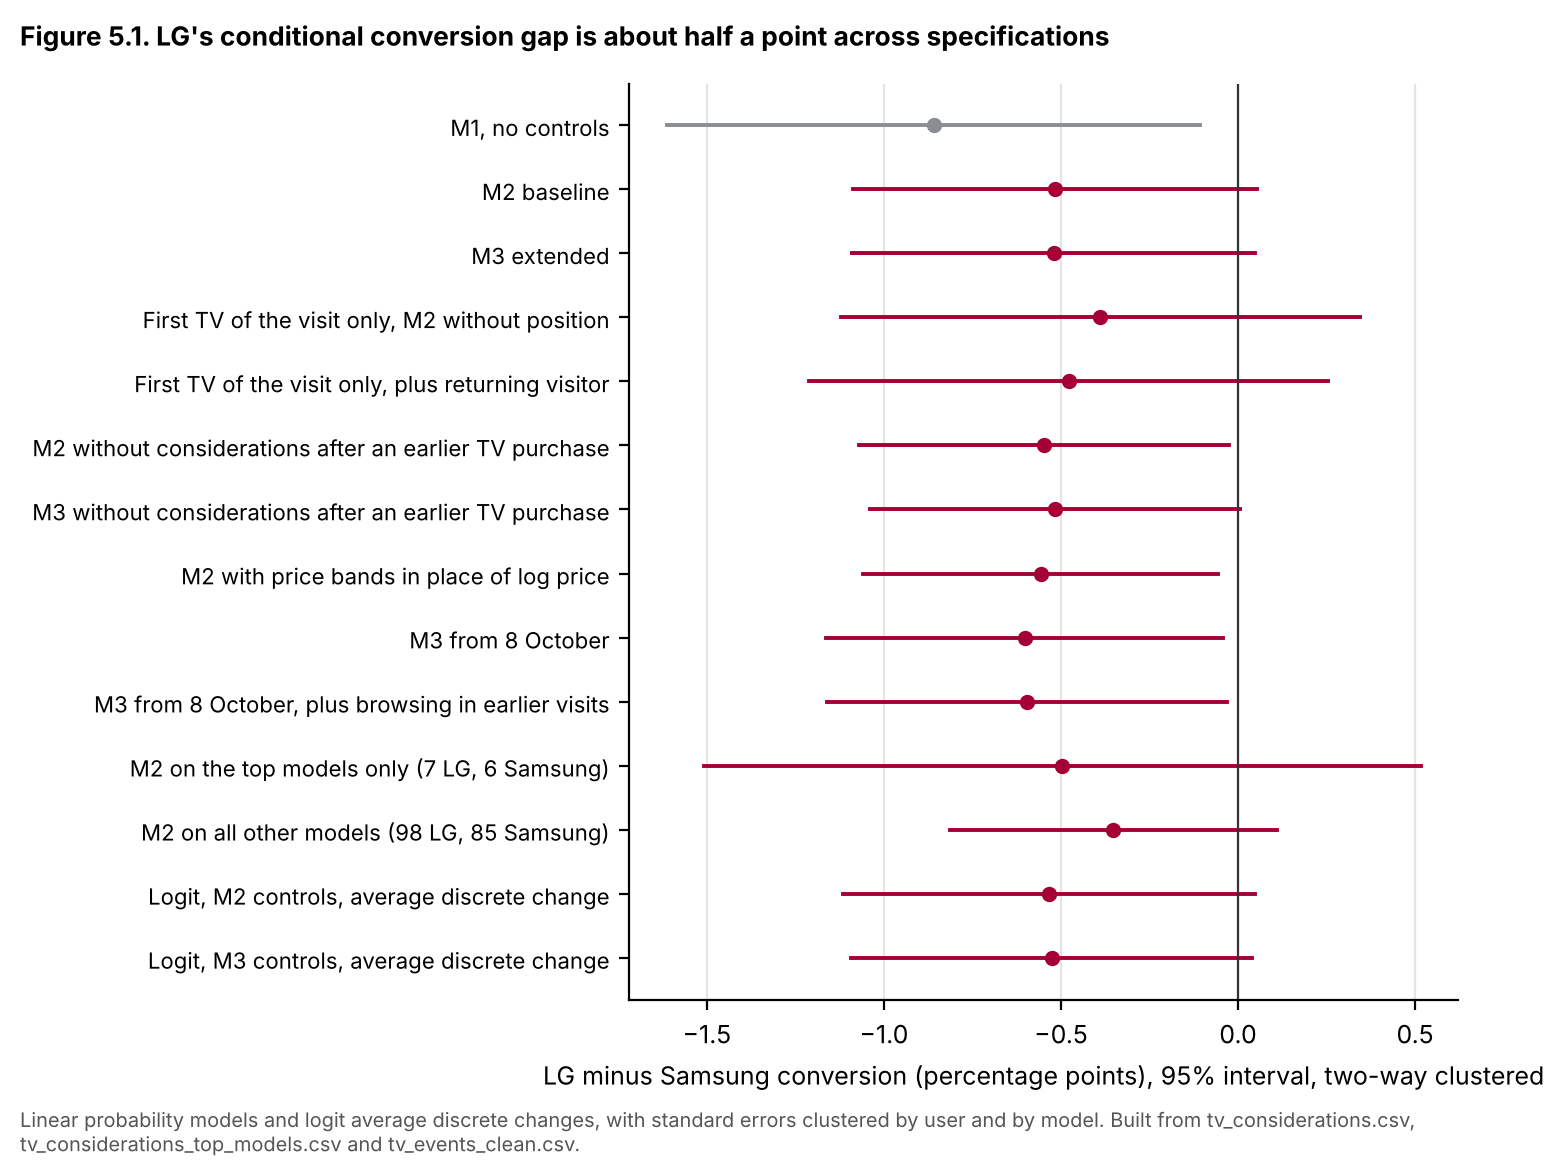

In [7]:
fig_rows = [('M1, no controls', fits['M1'].params['lg'], fits['M1'].bse['lg'])]
fig_rows += [(i, r['Coefficient (pp)'], r['Standard error (pp)']) for i, r in t54.iterrows()]
fig, ax = plt.subplots(figsize=(7.4, 5.6))
ypos = np.arange(len(fig_rows))[::-1]
for y0, (label, b, se) in zip(ypos, fig_rows):
    color = '#8A8D91' if label.startswith('M1') else '#A50034'
    ax.plot([b - 1.96 * se, b + 1.96 * se], [y0, y0], color=color, lw=1.4)
    ax.plot(b, y0, 'o', color=color, ms=4.5)
ax.axvline(0, color='#333333', lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels([r[0] for r in fig_rows], fontsize=8)
ax.set_xlabel('LG minus Samsung conversion (percentage points), 95% interval, two-way clustered')
fig.suptitle('Figure 5.1. LG\'s conditional conversion gap is about half a point across specifications',
             x=0.01, ha='left', fontsize=9.5, fontweight='bold')
ax.grid(axis='y', visible=False)
fig.text(0.01, -0.03, 'Linear probability models and logit average discrete changes, with standard errors clustered by user and '
         'by model. Built from tv_considerations.csv, tv_considerations_top_models.csv and tv_events_clean.csv.',
         fontsize=7.2, color='#555555', wrap=True)
fig.tight_layout()
fig.savefig(OUT / 'figures' / 'F5_1.png', bbox_inches='tight', facecolor='white')
EXHIBITS.append({'Exhibit': 'Figure 5.1', 'Title': 'LG minus Samsung conversion across Model 1 specifications and checks',
                 'Built from': ', '.join([F_CONS, F_TOP, F_EV])})
plt.show()

## 4. Model 2. Choice among the models opened before the purchase

Model 2 compares models that one shopper opened in one visit. In a visit that ended with one TV model bought, the models opened up to the moment of the purchase form the set the shopper chose from. The question is whether the LG model was less often the one bought, given its price, whether it was the first TV opened and whether it is a top model.

Each visit gets its own fixed effect. Everything that is the same throughout a visit drops out of the comparison, including the shopper's budget, urgency and taste, the device, whether they are a returning visitor, and the week. Visit fixed effects do not absorb brand-specific preferences of the shopper, or attributes of the models that the covariates leave out. A conditional logit estimates the model without estimating each visit's fixed effect separately.

**Choice sets.** The sample is built in four steps.
1. Start from visits with two or more TV considerations and exactly one purchased consideration. Visits with purchases of more than one model are left out, since a choice model needs one chosen option.
2. Find the time of the chosen model's first purchase event at or after its first view, from `tv_events_clean.csv`.
3. Drop any visit that also contains a purchase event for another product, including purchases that have no qualifying consideration.
4. Keep only the alternatives first viewed at or before the purchase time, then keep the visits that still have two or more alternatives.

An alternative first viewed in the same second as the purchase would count as opened before it. The code reports how many such alternatives there are.

**Assumptions.** The conditional logit assumes that the odds between two opened models do not depend on which other models were opened. The set of opened models is formed by the shopper's search and the site's displays, so it is observed rather than assigned. The sample covers only visits with a purchase and at least two options, so the estimate describes choices within those visits and is not a measure of conversion.

**Covariates.** These are LG and the other four brands (each against Samsung), log price, whether the model was the first TV opened in the visit, and whether it is a top model. With visit fixed effects, log price compares the models within the same visit.

In [8]:
X2 = ['lg', 'other_four', 'log_price', 'first_tv', 'top_model']
vis = cons.groupby('visit').agg(n=('product_id', 'size'), buys=('purchased', 'sum'))
cand = cons[cons['visit'].isin(vis.index[(vis['n'] >= 2) & (vis['buys'] == 1)])].copy()
purchases = events.loc[(events['event_type'] == 'purchase') & events['visit'].isin(cand['visit']),
                       ['visit', 'product_id', 'event_time']]
chosen = cand.loc[cand['purchased'] == 1, ['visit', 'product_id', 'first_view']]
ptime = chosen.merge(purchases, on=['visit', 'product_id'])
ptime = ptime[ptime['event_time'] >= ptime['first_view']].groupby('visit')['event_time'].min().rename('purchase_time')
other_buy = purchases.merge(chosen[['visit', 'product_id']], on='visit', suffixes=('', '_chosen'))
other_buy = set(other_buy.loc[other_buy['product_id'] != other_buy['product_id_chosen'], 'visit'])
cand = cand.join(ptime, on='visit')
assert cand['purchase_time'].notna().all()
late_alt = cand['first_view'] > cand['purchase_time']
same_second = (cand['first_view'] == cand['purchase_time']) & (cand['purchased'] == 0)
ch = cand[~late_alt & ~cand['visit'].isin(other_buy)]
ch = ch[ch.groupby('visit')['product_id'].transform('size') >= 2].sort_values(['visit', 'first_view']).reset_index(drop=True)
assert (ch.groupby('visit')['purchased'].sum() == 1).all() and (ch.groupby('visit')['first_tv'].sum() == 1).all()
by_visit = ch.groupby('visit').agg(has_lg=('lg', 'max'), has_samsung=('brand_group', lambda s: (s == 'samsung').any()))
hh = ch[ch['visit'].isin(by_visit.index[by_visit['has_lg'].astype(bool) & by_visit['has_samsung']])].reset_index(drop=True)
steps = pd.Series({
    'Visits with two or more considerations and one purchased consideration': cand['visit'].nunique(),
    'Alternatives in those visits': len(cand),
    'Visits with a purchase event for another product (dropped)': len(other_buy),
    'Alternatives first viewed after the purchase (dropped)': int(late_alt.sum()),
    'Visits containing such alternatives': cand.loc[late_alt, 'visit'].nunique(),
    'Alternatives first viewed in the same second as the purchase (kept)': int(same_second.sum()),
    'Visits in the final sample': ch['visit'].nunique(),
    'Alternatives in the final sample': len(ch),
    'Final visits that include an LG model': int(by_visit['has_lg'].sum()),
    'Final visits that ended in an LG purchase': int(ch.loc[ch['lg'] == 1, 'purchased'].sum()),
    'Final visits that include both LG and Samsung': hh['visit'].nunique(),
}, name='Count')
display(steps.to_frame())

,Count
Visits with two or more considerations and one purchased consideration,1265
Alternatives in those visits,4302
Visits with a purchase event for another product (dropped),1
Alternatives first viewed after the purchase (dropped),150
Visits containing such alternatives,89
Alternatives first viewed in the same second as the purchase (kept),0
Visits in the final sample,1220
Alternatives in the final sample,4105
Final visits that include an LG model,382
Final visits that ended in an LG purchase,188


The estimator below maximises the conditional logit likelihood by Newton's method and reports the largest absolute gradient at the solution, which should be close to zero. Its model-based standard errors are compared with those of the conditional logit in statsmodels, which checks the coefficients and the Hessian.

The clustered errors need a score for each row, so that rows can be grouped by user and by model. The score of a visit is the sum over its rows of (purchased − fitted probability) × covariate. Because the fitted probabilities in a visit sum to one, the same total is obtained when each row's covariate is measured as a deviation from the visit's probability-weighted average. The notebook uses these centred row scores. Unlike the raw row scores, they do not change when a constant is added to a covariate, which leaves the estimator unchanged, and that property is required for the grouping by model to be meaningful.

As an independent check of the clustered errors, a bootstrap resamples users with replacement (999 draws) and re-estimates the model each time. It is computed by weighting each user's visits by the number of times the user is drawn, which is equivalent to duplicating them. A bootstrap that resamples models is not well defined here, because each choice set contains several models.

In [9]:
def clogit_fit(X, y, g, w=None, tol=1e-10, max_iter=100):
    G, k = g.max() + 1, X.shape[1]
    w = np.ones(len(y)) if w is None else w
    wg = np.zeros(G); wg[g] = w

    def parts(b):
        v = X @ b
        vmax = np.full(G, -np.inf); np.maximum.at(vmax, g, v)
        e = np.exp(v - vmax[g])
        den = np.bincount(g, weights=e, minlength=G)
        p = e / den[g]
        ll = np.sum(w * y * (v - vmax[g] - np.log(den[g])))
        grad = ((w * (y - p))[:, None] * X).sum(0)
        spx = np.zeros((G, k)); np.add.at(spx, g, X * p[:, None])
        H = (X * (w * p)[:, None]).T @ X - (spx * wg[:, None]).T @ spx
        return ll, grad, H, p, spx

    b = np.zeros(k)
    for it in range(1, max_iter + 1):
        ll, grad, H, p, spx = parts(b)
        if np.abs(grad).max() < tol:
            break
        step, t = np.linalg.solve(H, grad), 1.0
        while parts(b + t * step)[0] < ll - 1e-12 and t > 1e-6:
            t /= 2
        b = b + t * step
    ll, grad, H, p, spx = parts(b)
    return b, H, p, spx, {'Newton iterations': it, 'Largest absolute gradient': float(np.abs(grad).max()),
                          'Log-likelihood': float(ll)}


def clogit(d, cols):
    X, y = d[cols].to_numpy(float), d['purchased'].to_numpy(float)
    g = pd.factorize(d['visit'])[0]
    b, H, p, spx, info = clogit_fit(X, y, g)
    Hinv = np.linalg.inv(H)
    s = (X - spx[g]) * (y - p)[:, None]

    def meat(codes):
        sc = np.zeros((codes.max() + 1, X.shape[1])); np.add.at(sc, codes, s)
        return len(sc) / (len(sc) - 1) * sc.T @ sc

    cu, cm = pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]
    cum = pd.factorize(d['user_id'] + '|' + d['product_id'])[0]
    V = Hinv @ (meat(cu) + meat(cm) - meat(cum)) @ Hinv
    se = np.sqrt(np.diag(V))
    ses = pd.DataFrame({'Two-way (user and model)': se, 'One-way by user': np.sqrt(np.diag(Hinv @ meat(cu) @ Hinv)),
                        'One-way by model': np.sqrt(np.diag(Hinv @ meat(cm) @ Hinv)),
                        'Model-based': np.sqrt(np.diag(Hinv))}, index=cols)
    est = pd.DataFrame({'Coefficient': b, 'Standard error': se, 'p-value, two-way clustered': 2 * stats.norm.sf(np.abs(b / se)),
                        'Odds ratio': np.exp(b), 'Odds ratio, 95% CI low': np.exp(b - 1.96 * se),
                        'Odds ratio, 95% CI high': np.exp(b + 1.96 * se)}, index=cols)
    return est, ses, V, info


m2_all, m2_ses, m2_V, m2_info = clogit(ch, X2)
m2_hh, _, _, _ = clogit(hh, X2)
from statsmodels.discrete.conditional_models import ConditionalLogit
ref = ConditionalLogit(ch['purchased'], ch[X2].astype(float), groups=pd.factorize(ch['visit'])[0]).fit(disp=False)
m2_ses['statsmodels model-based'] = ref.bse.to_numpy()
gap = np.abs(ref.params.to_numpy() - m2_all['Coefficient'].to_numpy()).max()
print(f"Largest coefficient difference from statsmodels {gap:.1e}; log-likelihood here {m2_info['Log-likelihood']:.4f}, "
      f"statsmodels {ref.llf:.4f}")
assert gap < 2e-3 and m2_info['Log-likelihood'] >= ref.llf - 1e-6

Xc, yc, gc = ch[X2].to_numpy(float), ch['purchased'].to_numpy(float), pd.factorize(ch['visit'])[0]
ucode, users = pd.factorize(ch['user_id'])
W = np.random.default_rng(SEED).multinomial(len(users), np.full(len(users), 1 / len(users)), size=999).astype(float)
boot = np.array([clogit_fit(Xc, yc, gc, w=wu[ucode])[0] for wu in W])
m2_ses['Bootstrap over users'] = boot.std(0, ddof=1)

within = ch[['purchased_pp'] + X2] - ch.groupby('visit')[['purchased_pp'] + X2].transform('mean')
within[['user_id', 'product_id']] = ch[['user_id', 'product_id']]
m2_lpm = ols2('purchased_pp ~ ' + ' + '.join(X2) + ' - 1', within)

NAMES2 = {'lg': 'LG (against Samsung)', 'other_four': 'Other four brands (against Samsung)', 'log_price': 'Log price',
          'first_tv': 'First TV opened in the visit', 'top_model': 'Top model (retrospective split)'}
fmt = lambda e, v: f"{e.loc[v, 'Coefficient']:.3f} ({e.loc[v, 'Standard error']:.3f})"
ci = lambda e: f"{e.loc['lg', 'Odds ratio']:.2f} ({e.loc['lg', 'Odds ratio, 95% CI low']:.2f} to {e.loc['lg', 'Odds ratio, 95% CI high']:.2f})"
t55 = pd.DataFrame({
    'Conditional logit, all choice visits': [fmt(m2_all, v) for v in X2],
    'Conditional logit, visits with LG and Samsung': [fmt(m2_hh, v) for v in X2],
    'Linear model with visit fixed effects (pp)': [f"{m2_lpm.params[v]:.2f} ({m2_lpm.bse[v]:.2f})" for v in X2],
}, index=[NAMES2[v] for v in X2])
t55.loc['Odds ratio for LG, 95% CI'] = [ci(m2_all), ci(m2_hh), '']
t55.loc['p-value for LG, two-way clustered'] = [f"{m2_all.loc['lg', 'p-value, two-way clustered']:.3f}",
                                                f"{m2_hh.loc['lg', 'p-value, two-way clustered']:.3f}", f"{m2_lpm.pvalues['lg']:.3f}"]
t55.loc['Visits'] = [f"{ch['visit'].nunique():,}", f"{hh['visit'].nunique():,}", f"{ch['visit'].nunique():,}"]
t55.loc['Alternatives'] = [f"{len(ch):,}", f"{len(hh):,}", f"{len(ch):,}"]
t55 = save_table('5.5', 'Model 2. Which of the models opened before the purchase was bought, with one fixed effect per visit',
                 t55, [F_CONS, F_EV])
display(t55)
t56 = m2_ses.round(3)
t56.index = [NAMES2[v] for v in X2]
t56 = save_table('5.6', 'Model 2 checks: standard errors of the conditional logit under different procedures', t56, [F_CONS, F_EV])
display(t56)
print(m2_info)

Largest coefficient difference from statsmodels 4.1e-04; log-likelihood here -1113.6421, statsmodels -1113.6421


Table 5.5. Model 2. Which of the models opened before the purchase was bought, with one fixed effect per visit
Built from tv_considerations.csv, tv_events_clean.csv. Saved to results/models/tables/T5_5.csv


,"Conditional logit, all choice visits","Conditional logit, visits with LG and Samsung",Linear model with visit fixed effects (pp)
LG (against Samsung),-0.247 (0.144),-0.233 (0.165),-6.73 (3.01)
Other four brands (against Samsung),0.238 (0.231),0.224 (0.419),6.27 (5.37)
Log price,0.406 (0.174),0.325 (0.256),7.80 (3.85)
First TV opened in the visit,-1.486 (0.098),-1.147 (0.209),-39.45 (1.80)
Top model (retrospective split),0.114 (0.173),0.264 (0.240),4.63 (3.43)
"Odds ratio for LG, 95% CI",0.78 (0.59 to 1.04),0.79 (0.57 to 1.09),
"p-value for LG, two-way clustered",0.086,0.157,0.025
Visits,"1,220",263,"1,220"
Alternatives,"4,105","1,311","4,105"


Table 5.6. Model 2 checks: standard errors of the conditional logit under different procedures
Built from tv_considerations.csv, tv_events_clean.csv. Saved to results/models/tables/T5_6.csv


,Two-way (user and model),One-way by user,One-way by model,Model-based,statsmodels model-based,Bootstrap over users
LG (against Samsung),0.144,0.137,0.127,0.140,0.140,0.141
Other four brands (against Samsung),0.231,0.174,0.213,0.177,0.177,0.179
Log price,0.174,0.129,0.164,0.148,0.148,0.127
First TV opened in the visit,0.098,0.090,0.088,0.088,0.088,0.092
Top model (retrospective split),0.173,0.125,0.161,0.121,0.121,0.128


{'Newton iterations': 6, 'Largest absolute gradient': 2.3092638912203256e-13, 'Log-likelihood': -1113.6420533979872}


To make the odds ratio concrete, the cell below works through two hypothetical visits. In each, the shopper opened exactly one LG and one Samsung model at the same price, neither of them a top model, and bought one of the two. In a two-option visit one model is necessarily opened first, so the two scenarios differ in which brand came first. Each scenario is compared with the probability the model implies when the brand coefficient is set to zero. The intervals come from 20,000 draws of the coefficients from their estimated distribution with the two-way covariance. These are probabilities of being the model chosen within such a visit, and they are not LG's conversion.

In [10]:
draws = np.random.default_rng(SEED).multivariate_normal(m2_all['Coefficient'].to_numpy(), m2_V, size=20000)
b_lg, b_first = draws[:, 0], draws[:, 3]
point_lg, point_first = m2_all.loc['lg', 'Coefficient'], m2_all.loc['first_tv', 'Coefficient']
logistic = lambda x: 1 / (1 + np.exp(-x))
scen = {
    'Samsung opened first, LG second': (logistic(point_lg - point_first), logistic(b_lg - b_first), logistic(-b_first)),
    'LG opened first, Samsung second': (logistic(point_lg + point_first), logistic(b_lg + b_first), logistic(b_first)),
}
rows = []
for k, (pt, sim, bench) in scen.items():
    rows.append({'Hypothetical visit': k, 'Probability the LG model is the one bought (%)': 100 * pt,
                 '95% interval low (%)': 100 * np.percentile(sim, 2.5), '95% interval high (%)': 100 * np.percentile(sim, 97.5),
                 'Same probability with the brand coefficient set to zero (%)': 100 * np.median(bench)})
display(pd.DataFrame(rows).set_index('Hypothetical visit').round(1))

,Probability the LG model is the one bought (%),95% interval low (%),95% interval high (%),Same probability with the brand coefficient set to zero (%)
Hypothetical visit,,,,
"Samsung opened first, LG second",77.5,70.5,83.3,81.5
"LG opened first, Samsung second",15.0,11.5,19.3,18.5


### What Model 2 shows

Among the models opened before the purchase, an LG model is somewhat less often the one bought than a Samsung model with the same covariates. The odds ratio for LG is 0.78, with a 95% interval from 0.59 to 1.04 and a two-way clustered p-value of 0.086. In a hypothetical two-option visit where Samsung was opened first, the LG model is bought in 77.5% of such visits (interval 70.5% to 83.3%), against 81.5% if brand made no difference. Where LG was opened first, the LG model is bought in 15.0% (11.5% to 19.3%), against 18.5%.

The visits that include both an LG and a Samsung model give a similar odds ratio (0.79, p = 0.16). The linear model with visit fixed effects gives an LG model a 6.7-point lower chance of being the model bought, with p = 0.025. The two specifications therefore differ in their statistical support, and the results should be described with both numbers.

The checks support the estimates and their standard errors. Newton's method converges in six iterations with a largest absolute gradient below 1e-12. The coefficients agree with statsmodels to within 0.0004 at the same log-likelihood, and the model-based errors match to three decimals. The bootstrap over users (0.141 for LG) agrees with the sandwich clustered by user (0.137). The two-way error for LG (0.144) is the largest of the procedures.

The first TV opened in a visit is much less likely to be the one bought (odds ratio 0.23), which fits the pattern that shoppers who go on browsing tend to buy something they find later. Within a visit, the more expensive of the models weighed is somewhat more likely to be bought. Price here probably tracks screen size and features, so this coefficient should not be read as a response to price.

## 5. Model 3. Considerations per observed product

Model 3 moves from considerations to TV models. Each of the 196 LG and Samsung models observed with at least one view is one observation, and the outcome is the number of considerations it drew over the two months. Models that were listed but never viewed in the sample are not observed, so the population is the set of viewed models and is not the full catalogue.

**What it measures.** The accounting identity in the exploration works at the level of the brand.

brand considerations = visits reaching the brand × considerations per reaching visit

A brand's considerations are also the sum of its products' considerations. A product's count equals the number of visits that opened that product, but summing over a brand's products counts a visit once for every model of the brand it opened. The per-product count therefore combines reach, the breadth of browsing within a visit, and the assortment, which matters because LG has 105 observed models and Samsung 91. Model 3 is an adjusted comparison of considerations per observed product. It is related to the reach part of the identity, and it is not a re-estimate or a test of the 70% share.

**Estimator.** A Poisson regression of the count on the LG indicator and log median price. Its LG coefficient b translates into a percentage difference, exp(b) − 1, in the expected count of an LG model compared with a Samsung model at the same median price, under the assumption that the expected count is an exponential function of the covariates. Robust errors (HC1) remain valid when the counts are more dispersed than a Poisson distribution, provided that the exponential mean is right. They do not correct a wrong mean, omitted product characteristics, or dependence between products that share shoppers. A bootstrap that resamples shoppers addresses the last point.

**Sensitivity.** The variants cover price bands, common price support, considerations per day of each model's observed activity span (from its first to its last recorded event, which is not a known listing period), removal of the top models of both brands, removal of Samsung's largest models, a check that drops one model at a time, and a linear regression of log considerations. The linear version models the mean of log counts instead of the mean of counts, so the difference between the two estimates shows how sensitive the comparison is to the scale and the mean specification.

In [11]:
span = events.groupby('product_id')['event_time'].agg(['min', 'max'])
mod = (ls.groupby('product_id')
         .agg(considerations=('purchased', 'size'), median_price=('price', 'median'), lg=('lg', 'max'),
              top_model=('top_model', 'max'))
         .join(span))
mod['log_median_price'] = np.log(mod['median_price'])
mod['activity_span_days'] = (mod['max'].dt.normalize() - mod['min'].dt.normalize()).dt.days + 1
mod['log_considerations'] = np.log(mod['considerations'])
mod['price_band'] = pd.cut(mod['median_price'], [0, 300, 450, 650, 1000, np.inf],
                           labels=['Under 300', '300 to 450', '450 to 650', '650 to 1,000', 'Over 1,000'])
lo_p, hi_p = mod.groupby('lg')['median_price'].min().max(), mod.groupby('lg')['median_price'].max().min()
common = mod[mod['median_price'].between(lo_p, hi_p)]
samsung_largest = mod[mod['lg'] == 0]['considerations'].nlargest(5).index
print(mod.groupby('lg')[['considerations', 'median_price']].median().rename(index={0: 'Samsung median', 1: 'LG median'}))

F3 = 'considerations ~ lg + log_median_price'
poisson = lambda f, d, offset=None: smf.glm(f, d, family=sm.families.Poisson(), offset=offset).fit(cov_type='HC1')
M3 = [
    ('Poisson, log median price (main)', poisson(F3, mod)),
    ('Poisson, price bands', poisson('considerations ~ lg + C(price_band)', mod)),
    (f'Poisson, common price support ({lo_p:.0f} to {hi_p:.0f})', poisson(F3, common)),
    ('Poisson, per day of observed activity span', poisson(F3, mod, offset=np.log(mod['activity_span_days']))),
    ('Poisson, without the 13 top models of both brands', poisson(F3, mod[mod['top_model'] == 0])),
    ('Poisson, without Samsung\'s largest model', poisson(F3, mod.drop(samsung_largest[:1]))),
    ('Poisson, without Samsung\'s three largest models', poisson(F3, mod.drop(samsung_largest[:3]))),
    ('Poisson, without Samsung\'s five largest models', poisson(F3, mod.drop(samsung_largest[:5]))),
    ('Linear, log considerations', smf.ols('log_considerations ~ lg + log_median_price', mod).fit(cov_type='HC1')),
]
t57 = pd.DataFrame([{'LG coefficient': r.params['lg'], 'Standard error': r.bse['lg'],
                     'LG against Samsung (%)': 100 * (np.exp(r.params['lg']) - 1),
                     '95% CI low (%)': 100 * (np.exp(r.params['lg'] - 1.96 * r.bse['lg']) - 1),
                     '95% CI high (%)': 100 * (np.exp(r.params['lg'] + 1.96 * r.bse['lg']) - 1),
                     'p-value': r.pvalues['lg'], 'Models': int(r.nobs)} for _, r in M3],
                   index=[k for k, _ in M3]).round(3)
t57.index.name = 'Specification'

loo = pd.Series({p: smf.glm(F3, mod.drop(p), family=sm.families.Poisson()).fit().params['lg'] for p in mod.index})
uc = pd.factorize(ls['user_id'])[0]
pc = pd.Categorical(ls['product_id'], categories=mod.index).codes
counts_by_user = sparse.csr_matrix((np.ones(len(ls)), (uc, pc)), shape=(uc.max() + 1, len(mod)))
Xm = sm.add_constant(mod[['lg', 'log_median_price']].to_numpy(float))
start = M3[0][1].params.to_numpy()
Wp = np.random.default_rng(SEED).poisson(1.0, size=(999, uc.max() + 1)).astype(float)
boot3 = np.array([sm.GLM(np.asarray(counts_by_user.T @ w).ravel(), Xm, family=sm.families.Poisson()).fit(
    start_params=start).params[1] for w in Wp])
t57 = save_table('5.7', 'Model 3. Considerations per observed LG model against a Samsung model at the same price', t57,
                 [F_CONS, F_EV])
display(t57)
print(f"Dropping one model at a time, the main LG coefficient ranges from {loo.min():.3f} to {loo.max():.3f} "
      f"(main {M3[0][1].params['lg']:.3f}). The three most influential models:")
influential = loo.sub(M3[0][1].params['lg']).abs().nlargest(3).index
display(pd.DataFrame({'Brand': mod.loc[influential, 'lg'].map({1: 'LG', 0: 'Samsung'}),
                      'Considerations': mod.loc[influential, 'considerations'],
                      'Rank within its brand': [int((mod.loc[mod['lg'] == mod.loc[p, 'lg'], 'considerations'] > mod.loc[p, 'considerations']).sum()) + 1
                                                for p in influential],
                      'LG coefficient without it': loo[influential].round(3)}))
print(f"Bootstrap over shoppers (999 Poisson-weighted draws): standard error {boot3.std(ddof=1):.3f}, "
      f"95% interval {np.percentile(boot3, 2.5):.3f} to {np.percentile(boot3, 97.5):.3f}; HC1 standard error {M3[0][1].bse['lg']:.3f}")

                considerations  median_price
lg                                          
Samsung median            86.0        849.19
LG median                 65.0        771.68


Table 5.7. Model 3. Considerations per observed LG model against a Samsung model at the same price
Built from tv_considerations.csv, tv_events_clean.csv. Saved to results/models/tables/T5_7.csv


,LG coefficient,Standard error,LG against Samsung (%),95% CI low (%),95% CI high (%),p-value,Models
Specification,,,,,,,
"Poisson, log median price (main)",-0.890,0.299,-58.952,-77.174,-26.183,0.003,196
"Poisson, price bands",-0.951,0.306,-61.356,-78.800,-29.561,0.002,196
"Poisson, common price support (231 to 2574)",-0.934,0.297,-60.692,-78.036,-29.654,0.002,194
"Poisson, per day of observed activity span",-0.993,0.282,-62.965,-78.694,-35.624,0.000,196
"Poisson, without the 13 top models of both brands",-0.819,0.204,-55.916,-70.448,-34.236,0.000,183
"Poisson, without Samsung's largest model",-0.737,0.291,-52.128,-72.961,-15.244,0.011,195
"Poisson, without Samsung's three largest models",-0.495,0.279,-39.048,-64.752,5.398,0.076,193
"Poisson, without Samsung's five largest models",-0.281,0.270,-24.487,-55.525,28.211,0.298,191
"Linear, log considerations",-0.290,0.286,-25.139,-57.247,31.083,0.311,196


Dropping one model at a time, the main LG coefficient ranges from -1.003 to -0.737 (main -0.890). The three most influential models:


,Brand,Considerations,Rank within its brand,LG coefficient without it
P000507,Samsung,9106,1,-0.737
P000554,Samsung,6865,2,-0.766
P000640,LG,2723,1,-1.003


Bootstrap over shoppers (999 Poisson-weighted draws): standard error 0.012, 95% interval -0.914 to -0.867; HC1 standard error 0.299


### What Model 3 shows

At the same median price, an observed LG model draws about 59% fewer considerations than an observed Samsung model, with a 95% interval from 26% to 77% fewer. The estimate is similar with price bands (61% fewer), on common price support (61% fewer), per day of observed activity span (63% fewer) and without the top models of both brands (56% fewer). Resampling shoppers barely moves the estimate (standard error 0.012 against 0.299 from HC1), so its uncertainty comes from differences between products, and the dependence created by shared shoppers is negligible.

The estimate is sensitive to Samsung's largest models. Dropping any single model leaves the coefficient between −1.00 and −0.74, and the three most influential models are Samsung's two largest and LG's largest. Dropping Samsung's three largest models while keeping LG's gives 39% fewer considerations (p = 0.08), and dropping its five largest gives 24% fewer, with an interval that includes zero. The linear model of log counts gives 25% fewer (interval −57% to +31%). The Poisson estimate gives more weight to models with many considerations, so the difference between the two estimates and the removal checks both show that much of the per-product gap comes from a few Samsung models with very large traffic. This agrees with the top-model split in the exploration.

## 6. Model 4. Price changes within a model (optional extension)

Most TV models changed recorded price during the two months (80% of LG models and 68% of Samsung models). Model 4 describes how traffic and conversion move when the same model's recorded price changes. A model fixed effect gives each TV model its own baseline, which absorbs everything fixed about it, such as brand, screen size, page and usual placement. The price coefficient then comes from changes in each model's own price over time. A week or day fixed effect absorbs shifts common to all models in that period.

- **4a, conversion.** A linear probability model of purchase on log price, with model and week fixed effects and position in the visit, on the 74,712 LG and Samsung considerations, using the price at each first view. An LG × log price term asks whether the association differs for LG. LG's main effect is absorbed by the model fixed effects.
- **4b, traffic.** A Poisson regression of the number of considerations a model draws each day on its log price, with model and day fixed effects, clustered by model. The panel covers each model from the first to the last day of its observed activity span. The daily price is the median recorded price over the model's events that day. On days without events no price is recorded, and the last recorded price is carried forward (or the first one carried back).
- **4c, traffic by week.** The same with weeks in place of days.

The measurement limits are set out by the cell below. It counts the model-days whose price is carried over and compares the main estimate with an estimate that uses only days with a recorded price. It also checks two alternative rules, prices recorded on view events only and an activity span built from views only.

In [12]:
TEN = np.log(1.1)
r4a = ols2('purchased_pp ~ log_price + log_price:lg + C(product_id) + C(week) + C(position)', ls)
r4a0 = ols2('purchased_pp ~ log_price + C(product_id) + C(week) + C(position)', ls)
ev = events[events['product_id'].isin(mod.index)].assign(day=lambda d: d['event_time'].dt.normalize())


def price_panel(freq='D', price_from='all', span_from='all'):
    to_period = (lambda s: s) if freq == 'D' else (lambda s: s - pd.to_timedelta(s.dt.weekday, unit='D'))
    src = ev if price_from == 'all' else ev[ev['event_type'] == 'view']
    rec = src.assign(period=to_period(src['day'])).groupby(['product_id', 'period'])['price'].median()
    win = (ev if span_from == 'all' else ev[ev['event_type'] == 'view']).groupby('product_id')['day'].agg(['min', 'max'])
    out = []
    for pid, (lo, hi) in win.iterrows():
        lo, hi = to_period(pd.Series([lo, hi])).tolist()
        periods = pd.date_range(lo, hi, freq='D' if freq == 'D' else '7D')
        r = rec.loc[pid].reindex(periods)
        out.append(pd.DataFrame({'product_id': pid, 'period': periods, 'price': r.ffill().bfill().to_numpy(),
                                 'price_recorded': r.notna().to_numpy()}))
    out = pd.concat(out, ignore_index=True)
    n = ls.assign(period=to_period(ls['first_view'].dt.normalize())).groupby(['product_id', 'period']).size()
    out = out.merge(n.rename('considerations'), on=['product_id', 'period'], how='left').fillna({'considerations': 0})
    assert out['considerations'].sum() == len(ls)
    out['log_price'] = np.log(out['price'])
    out['lg'] = out['product_id'].map(mod['lg'])
    out['period_s'] = out['period'].dt.strftime('%m-%d')
    return out


def ppml_fe(d, inter=False):
    f = 'considerations ~ log_price' + (' + log_price:lg' if inter else '') + ' + C(product_id) + C(period_s)'
    return smf.glm(f, d, family=sm.families.Poisson()).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['product_id'])[0]})


daily, weekly = price_panel('D'), price_panel('W')
print(pd.crosstab(daily['price_recorded'], daily['considerations'] > 0, rownames=['Price recorded that day'],
                  colnames=['At least one consideration that day']))
print(f"Daily panel: {len(daily):,} model-days, price carried over on {(~daily['price_recorded']).mean():.1%}; "
      f"weekly panel: {len(weekly):,} model-weeks, price carried over on {(~weekly['price_recorded']).mean():.1%}")
dev = ls['log_price'] - ls.groupby('product_id')['log_price'].transform('mean')
print(f"Within-model standard deviation of log price at the first view: {dev.std():.3f}")


def effect(r, term, kind):
    b, se = r.params[term], r.bse[term]
    if kind == 'pp':
        e, lo, hi, unit = b * TEN, (b - 1.96 * se) * TEN, (b + 1.96 * se) * TEN, 'pp'
    else:
        e, lo, hi = [100 * (np.exp(x * TEN) - 1) for x in (b, b - 1.96 * se, b + 1.96 * se)]
        unit = '%'
    return {'Coefficient on log price': b, 'Standard error': se, 'Associated change for a 10% higher price': e,
            '95% CI low': lo, '95% CI high': hi, 'Unit': unit, 'p-value': r.pvalues[term], 'Observations': int(r.nobs)}


t58 = pd.DataFrame({
    '4a. Conversion, both brands': effect(r4a0, 'log_price', 'pp'),
    '4a. Conversion, LG minus Samsung': effect(r4a, 'log_price:lg', 'pp'),
    '4b. Daily considerations, both brands': effect(ppml_fe(daily), 'log_price', '%'),
    '4b. Daily considerations, LG relative to Samsung': effect(ppml_fe(daily, True), 'log_price:lg', '%'),
    '4b. Daily, only days with a recorded price': effect(ppml_fe(daily[daily['price_recorded']]), 'log_price', '%'),
    '4b. Daily, prices recorded on views only': effect(ppml_fe(price_panel('D', price_from='view')), 'log_price', '%'),
    '4b. Daily, activity span from views only': effect(ppml_fe(price_panel('D', span_from='view')), 'log_price', '%'),
    '4c. Weekly considerations, both brands': effect(ppml_fe(weekly), 'log_price', '%'),
    '4c. Weekly considerations, LG relative to Samsung': effect(ppml_fe(weekly, True), 'log_price:lg', '%'),
}).T
num = [c for c in t58.columns if c != 'Unit']
t58[num] = t58[num].astype(float).round(3)
t58.index.name = 'Model'
t58 = save_table('5.8', 'Model 4. Conversion and traffic when the same model\'s recorded price changes (optional extension)',
                 t58, [F_CONS, F_EV])
display(t58)

At least one consideration that day  False  True 
Price recorded that day                          
False                                 3029      0
True                                     2   6374
Daily panel: 9,405 model-days, price carried over on 32.2%; weekly panel: 1,461 model-weeks, price carried over on 6.3%
Within-model standard deviation of log price at the first view: 0.038


Table 5.8. Model 4. Conversion and traffic when the same model's recorded price changes (optional extension)
Built from tv_considerations.csv, tv_events_clean.csv. Saved to results/models/tables/T5_8.csv


,Coefficient on log price,Standard error,Associated change for a 10% higher price,95% CI low,95% CI high,Unit,p-value,Observations
Model,,,,,,,,
"4a. Conversion, both brands",3.883,2.930,0.370,-0.177,0.917,pp,0.185,74712.0
"4a. Conversion, LG minus Samsung",1.407,5.762,0.134,-0.942,1.211,pp,0.807,74712.0
"4b. Daily considerations, both brands",-2.678,0.411,-22.524,-28.244,-16.347,%,0.000,9405.0
"4b. Daily considerations, LG relative to Samsung",-0.918,0.829,-8.377,-21.522,6.968,%,0.268,9405.0
"4b. Daily, only days with a recorded price",-2.327,0.381,-19.891,-25.389,-13.988,%,0.000,6376.0
"4b. Daily, prices recorded on views only",-2.675,0.409,-22.503,-28.210,-16.343,%,0.000,9405.0
"4b. Daily, activity span from views only",-2.678,0.411,-22.524,-28.244,-16.347,%,0.000,9405.0
"4c. Weekly considerations, both brands",-2.684,0.614,-22.571,-30.967,-13.153,%,0.000,1461.0
"4c. Weekly considerations, LG relative to Samsung",-1.874,1.272,-16.354,-34.047,6.085,%,0.141,1461.0


### What Model 4 shows

In the daily panel the price is carried over on 32.2% of model-days, and all of those days have no consideration. Only two days have a recorded price and no consideration. The days that pull the traffic estimate down are therefore the days whose price was never observed, so the estimate depends on the assumption that a model's price stays at its last recorded value until the next event. Using only days with a recorded price gives 20% fewer considerations for a 10% higher price, against 23% in the main daily estimate. Prices recorded on view events only, and an activity span built from views only, give practically the same estimate as the main rule (22.5% fewer), so the choice of event type for prices and spans does not matter here. The weekly panel carries the price over on 6.3% of model-weeks and gives 23% fewer considerations.

Conversion shows no detectable association with the same model's price (+0.37 points for a 10% higher price, interval −0.18 to 0.92). LG's associations do not differ clearly from Samsung's on either measure.

These results describe associations under the stated price rule. The retailer may feature a model when its price changes, which the data do not show, and the price changes are small (a within-model standard deviation of about 4%). The model supports no causal elasticity, traffic lift or discount recommendation. The absence of a conversion association also does not show that price works only through traffic. Model 4 stays outside the central argument of the report.

## 7. What the models show, and what goes into the report

**Conversion.** Conditional on the observed browsing state, price and week, LG converts about half a point less than Samsung (Model 1). The size is stable across eleven specifications and the logit. Its statistical support is borderline. The baseline gives p = 0.075 under the primary two-way procedure, four alternatives give p between 0.030 and 0.040, and the wild bootstrap over models gives p of 0.06 or more throughout. Position in the visit accounts for about 0.32 points of the change in the fitted LG coefficient, or 37% of the raw coefficient, which matches the shopper-mix result of the exploration. Among the models opened before a purchase, an LG model is somewhat less often the one bought (Model 2, odds ratio 0.78, p = 0.086, and 6.7 points lower in the linear version, p = 0.025).

**Considerations per product.** At the same price, an observed LG model draws about 59% fewer considerations than an observed Samsung model (Model 3). Much of this difference comes from a few Samsung models with very large traffic. The result is consistent with the reach part of the accounting split, while measuring a per-product quantity that also reflects browsing breadth and assortment.

**Price.** Model 4 is an optional extension that rests on carried-over prices, and it stays out of the central argument.

**Suggested exhibits for Section 5**
- Table 5.1 with columns M1 to M3, shortened to the LG row, the position or history rows, price, the fixed-effect line, both p-values and the number of considerations.
- Figure 5.1, which shows the size of the conditional gap and its stability.
- One or two sentences each on Table 5.3 (position accounts for most of the change in the coefficient), Table 5.5 (the odds ratio, with the linear version beside it) and Table 5.7 (59% fewer considerations per observed product, with its sensitivity to Samsung's largest models).

**Wording**
- Write "conditional on observed browsing state, price and week" for Model 1 and avoid "for the same shopper".
- Describe the Gelbach pieces as contributions to the change in the fitted coefficient.
- Describe Model 3 as a comparison of considerations per observed product.
- Report p-values with the procedure that produced them, and avoid a global claim that all adjusted differences are indistinguishable from zero.

**Methods.** The Gelbach decomposition, the conditional logit and Poisson regression may go beyond the methods taught in the course. Check with the instructor before relying on them in the report. Model 1 and the Model 3 comparison can be presented without the decomposition if needed.

The cell below saves the index of exhibits with the files each one is built from.

## 8. Record of specification decisions

| Decision | When it was made | Reason |
| --- | --- | --- |
| Outcome, unit of analysis and two-way clustering by user and model | Before this notebook, in the exploration | Conventions of `02_preliminary_analysis.py` |
| The four models and the controls of M1 to M4 | After the exploration and before any model in this notebook was estimated | Controls known at the first view, chosen for timing and purpose |
| The first-TV check | Before estimation, after a question about position in the visit | Tests whether the gap survives at a single search stage |
| Symmetric history variables | Before estimation | `samsung_opened_before` meant different things for the two brands |
| Centred row scores in Model 2's clustered errors | After the first estimates, which gave implausibly large errors with raw row scores | Raw row scores change when a constant is added to a covariate |
| Per-day offset in Model 3 in place of days as a covariate | After the first estimates | The span is partly an outcome of traffic, so it enters only as a sensitivity |
| Choice sets closed at the purchase time, visits with another purchase dropped | After the review of step 03 | Alternatives opened after the purchase cannot be part of the choice. The odds ratio for LG was 0.78 before and after the change |
| Diagnostics, bootstrap intervals for the decomposition, influence and shopper-bootstrap checks for Model 3, price-rule checks for Model 4 | After the review of step 03 | Requested by the review |

In [13]:
index = pd.DataFrame(EXHIBITS)
index.to_csv(OUT / 'exhibit_index.csv', index=False)
display(index)

,Exhibit,Title,Built from
0,Table 5.1,"Model 1. Conversion of LG and Samsung considerations, linear probability mod...",tv_considerations.csv
1,Table 5.2,Model 1 diagnostics: fitted values of the linear model and common support of...,tv_considerations.csv
2,Table 5.3,"Gelbach decomposition of the change in the fitted LG coefficient from M1, wi...",tv_considerations.csv
3,Table 5.4,"Model 1 robustness checks, LG minus Samsung conversion conditional on the co...","tv_considerations.csv, tv_considerations_top_models.csv, tv_events_clean.csv"
4,Figure 5.1,LG minus Samsung conversion across Model 1 specifications and checks,"tv_considerations.csv, tv_considerations_top_models.csv, tv_events_clean.csv"
5,Table 5.5,"Model 2. Which of the models opened before the purchase was bought, with one...","tv_considerations.csv, tv_events_clean.csv"
6,Table 5.6,Model 2 checks: standard errors of the conditional logit under different pro...,"tv_considerations.csv, tv_events_clean.csv"
7,Table 5.7,Model 3. Considerations per observed LG model against a Samsung model at the...,"tv_considerations.csv, tv_events_clean.csv"
8,Table 5.8,Model 4. Conversion and traffic when the same model's recorded price changes...,"tv_considerations.csv, tv_events_clean.csv"
